Upload:
1. plasma_G1_1min_FINAL.csv
2. plasma_G2_10min_FINAL.csv


Saving plasma_G1_1min_FINAL.csv to plasma_G1_1min_FINAL.csv
Saving plasma_G2_10min_FINAL.csv to plasma_G2_10min_FINAL.csv

Uploaded files:
- plasma_G1_1min_FINAL.csv
- plasma_G2_10min_FINAL.csv

G1: plasma_G1_1min_FINAL.csv
G2: plasma_G2_10min_FINAL.csv

DATASETS LOADED
G1 observations: 26077
G2 observations: 1686

FINAL G1 / G2 CHARACTERIZATION
       Group     N                     Start                       End  Duration_h  Duration_days  Nominal_interval_min  Median_interval_min  Mean_interval_min  Regular_interval_pct  Number_of_gaps  Estimated_missing  Estimated_missing_pct  Maximum_gap_min  Mean_temperature_C  Median_temperature_C  SD_temperature_C  Minimum_temperature_C  Maximum_temperature_C
 G1 (~1 min) 26077 2026-08-21 17:43:38+00:00 2026-09-08 21:40:00+00:00  435.939444      18.164144                     1                  1.0           1.003082             99.927136              13                 86               0.328708        40.016667          -30.581328             

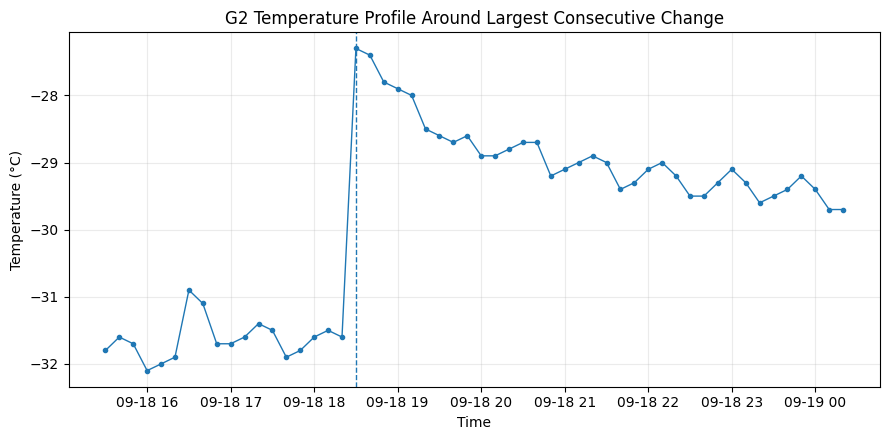


G1 / G2 ACF AT COMMON LAGS
 Approx_lag_min   G1_ACF   G2_ACF
             50 0.810121 0.865487
            100 0.691304 0.792836
            150 0.611726 0.725306
            200 0.483809 0.657571
            250 0.387069 0.596223
            300 0.287389 0.542669

Approximate 95% confidence thresholds:
G1: 0.022389
G2: 0.071809


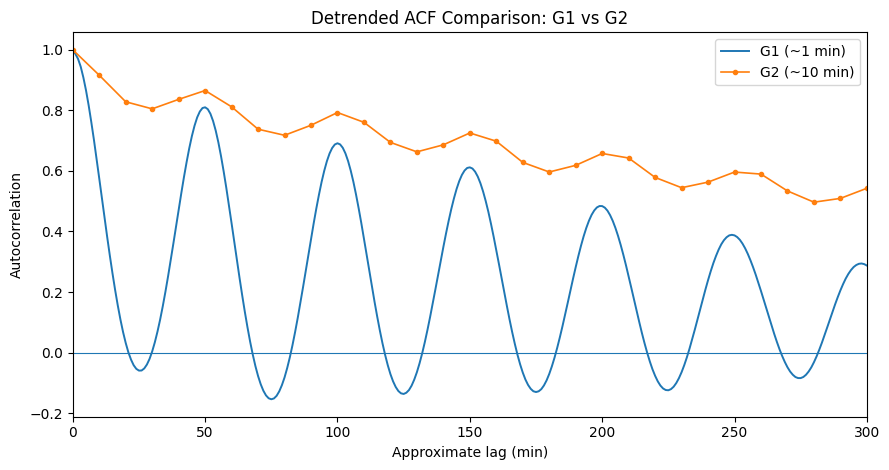


MANUSCRIPT-READY G1 / G2 TABLE
                             Metric           G1          G2
                       Observations 26077.000000 1686.000000
      Chronological coverage (days)    18.164144   14.194329
 Nominal acquisition interval (min)     1.000000   10.000000
     Median observed interval (min)     1.000000   10.000000
Intervals within nominal regime (%)    99.927136   99.406528
 Estimated missing observations (%)     0.328708   17.675781
         Number of acquisition gaps    13.000000    5.000000
              Mean temperature (°C)   -30.581328  -31.092171
            Median temperature (°C)   -30.500000  -31.500000
                Temperature SD (°C)     0.679628    0.972218

FILES GENERATED
- FINAL_G1_G2_characterization.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

- FINAL_G1_G2_manuscript_table.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (12 outputs left out)

- G2_largest_temperature_change.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


FINAL VALIDATION COMPLETED
G1 and G2 were analyzed as independent chronological acquisition regimes.
No causal temperature difference between G1 and G2 is inferred from their descriptive statistics.
The controlled sampling-resolution experiment remains the systematic subsampling analysis performed within G1.


In [1]:
# ============================================================
# PAPER 02 - HRFEST 2026
# FINAL G1 + G2 COMPARATIVE VALIDATION
#
# PURPOSE:
# 1. Summarize G1 (~1-min real acquisition)
# 2. Summarize G2 (~10-min real acquisition)
# 3. Compare acquisition characteristics
# 4. Confirm ~50-min recurrent thermal structure
# 5. Identify largest consecutive temperature changes in G2
# 6. Generate compact tables for the manuscript
#
# IMPORTANT:
# G1 and G2 correspond to DIFFERENT chronological periods.
# Therefore, differences in mean temperature, SD, extrema, etc.
# must NOT be attributed causally to sampling interval.
# ============================================================

!pip -q install statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.signal import detrend, find_peaks
from statsmodels.tsa.stattools import acf


# ============================================================
# 1. UPLOAD BOTH FILES
# ============================================================

print("Upload:")
print("1. plasma_G1_1min_FINAL.csv")
print("2. plasma_G2_10min_FINAL.csv")

uploaded = files.upload()

print("\nUploaded files:")
for name in uploaded.keys():
    print("-", name)


# ============================================================
# 2. IDENTIFY G1 AND G2 FILES
# ============================================================

g1_filename = None
g2_filename = None

for name in uploaded.keys():

    lower = name.lower()

    if "g1" in lower:
        g1_filename = name

    elif "g2" in lower:
        g2_filename = name


if g1_filename is None or g2_filename is None:

    raise ValueError(
        "Could not automatically identify G1 and G2 files. "
        "Make sure filenames contain G1 and G2."
    )


print("\nG1:", g1_filename)
print("G2:", g2_filename)


# ============================================================
# 3. LOAD AND CLEAN
# ============================================================

def load_dataset(filename):

    df = pd.read_csv(filename)

    df["datetime"] = pd.to_datetime(
        df["datetime"],
        errors="coerce",
        utc=True
    )

    df["dsTemperature"] = pd.to_numeric(
        df["dsTemperature"],
        errors="coerce"
    )

    df = (
        df
        .dropna(
            subset=[
                "datetime",
                "dsTemperature"
            ]
        )
        .sort_values("datetime")
        .drop_duplicates(
            subset=["datetime"]
        )
        .reset_index(drop=True)
    )

    df["interval_min"] = (
        df["datetime"]
        .diff()
        .dt.total_seconds()
        / 60
    )

    return df


g1 = load_dataset(g1_filename)
g2 = load_dataset(g2_filename)


print("\n====================================================")
print("DATASETS LOADED")
print("====================================================")

print("G1 observations:", len(g1))
print("G2 observations:", len(g2))


# ============================================================
# 4. GENERAL CHARACTERIZATION FUNCTION
# ============================================================

def characterize_dataset(
    df,
    group_name,
    nominal_interval,
    regular_low,
    regular_high,
    gap_threshold
):

    start = df["datetime"].min()
    end = df["datetime"].max()

    duration_h = (
        end - start
    ).total_seconds() / 3600

    duration_days = (
        duration_h / 24
    )

    intervals = (
        df["interval_min"]
        .dropna()
    )

    regular = (
        (intervals >= regular_low)
        &
        (intervals <= regular_high)
    )

    regular_pct = (
        regular.mean()
        * 100
    )

    gaps = df[
        df["interval_min"]
        > gap_threshold
    ].copy()

    if len(gaps) > 0:

        gaps["estimated_missing"] = np.maximum(

            np.round(
                gaps["interval_min"]
                / nominal_interval
            ).astype(int) - 1,

            0
        )

        missing = int(
            gaps["estimated_missing"].sum()
        )

        max_gap = (
            gaps["interval_min"].max()
        )

    else:

        missing = 0
        max_gap = 0


    expected = (
        len(df) + missing
    )

    missing_pct = (
        100 * missing / expected
        if expected > 0
        else np.nan
    )


    temp = df["dsTemperature"]


    return {

        "Group":
            group_name,

        "N":
            len(df),

        "Start":
            start,

        "End":
            end,

        "Duration_h":
            duration_h,

        "Duration_days":
            duration_days,

        "Nominal_interval_min":
            nominal_interval,

        "Median_interval_min":
            intervals.median(),

        "Mean_interval_min":
            intervals.mean(),

        "Regular_interval_pct":
            regular_pct,

        "Number_of_gaps":
            len(gaps),

        "Estimated_missing":
            missing,

        "Estimated_missing_pct":
            missing_pct,

        "Maximum_gap_min":
            max_gap,

        "Mean_temperature_C":
            temp.mean(),

        "Median_temperature_C":
            temp.median(),

        "SD_temperature_C":
            temp.std(ddof=1),

        "Minimum_temperature_C":
            temp.min(),

        "Maximum_temperature_C":
            temp.max()
    }


# ============================================================
# 5. G1 / G2 SUMMARY
# ============================================================

g1_summary = characterize_dataset(

    g1,

    "G1 (~1 min)",

    nominal_interval=1,

    regular_low=0.5,
    regular_high=1.5,

    gap_threshold=1.5
)


g2_summary = characterize_dataset(

    g2,

    "G2 (~10 min)",

    nominal_interval=10,

    regular_low=8,
    regular_high=12,

    gap_threshold=15
)


summary = pd.DataFrame([
    g1_summary,
    g2_summary
])


print("\n====================================================")
print("FINAL G1 / G2 CHARACTERIZATION")
print("====================================================")

print(
    summary.to_string(
        index=False
    )
)


# ============================================================
# 6. TOTAL MONITORING PERIOD
# ============================================================
#
# IMPORTANT:
# This is the sum of chronological coverage of the two
# acquisition regimes, NOT continuous valid-data availability.
# ============================================================

total_duration_h = (
    g1_summary["Duration_h"]
    +
    g2_summary["Duration_h"]
)

total_duration_days = (
    total_duration_h / 24
)

total_observations = (
    len(g1)
    +
    len(g2)
)


print("\n====================================================")
print("TOTAL EXPERIMENTAL COVERAGE")
print("====================================================")

print(
    "Total recorded observations:",
    total_observations
)

print(
    "Combined chronological coverage:",
    round(
        total_duration_h,
        4
    ),
    "hours"
)

print(
    "Combined chronological coverage:",
    round(
        total_duration_days,
        4
    ),
    "days"
)

print(
    "\nNOTE: chronological coverage includes periods "
    "containing acquisition gaps."
)


# ============================================================
# 7. FIND LARGEST G2 CONSECUTIVE TEMPERATURE CHANGES
# ============================================================
#
# Only pairs separated by 8-12 min are evaluated.
# This avoids treating large outages as ordinary consecutive
# observations.
# ============================================================

g2["delta_temp_C"] = (
    g2["dsTemperature"]
    .diff()
)

g2["abs_delta_temp_C"] = (
    g2["delta_temp_C"]
    .abs()
)

g2["previous_datetime"] = (
    g2["datetime"]
    .shift(1)
)

g2["previous_temperature_C"] = (
    g2["dsTemperature"]
    .shift(1)
)


valid_pair = (
    (g2["interval_min"] >= 8)
    &
    (g2["interval_min"] <= 12)
)


largest_changes = (

    g2.loc[
        valid_pair,
        [
            "previous_datetime",
            "datetime",

            "interval_min",

            "previous_temperature_C",
            "dsTemperature",

            "delta_temp_C",
            "abs_delta_temp_C",

            "doorStatus"
        ]
    ]

    .sort_values(
        "abs_delta_temp_C",
        ascending=False
    )

    .head(20)

    .reset_index(drop=True)
)


print("\n====================================================")
print("20 LARGEST VALID CONSECUTIVE G2 TEMPERATURE CHANGES")
print("====================================================")

print(
    largest_changes
    .to_string(index=False)
)


# ============================================================
# 8. SPECIFIC MAXIMUM G2 EVENT
# ============================================================

maximum_event = (
    largest_changes.iloc[0]
)


print("\n====================================================")
print("MAXIMUM VALID G2 TEMPERATURE CHANGE")
print("====================================================")

print(
    "Previous timestamp:",
    maximum_event[
        "previous_datetime"
    ]
)

print(
    "Current timestamp:",
    maximum_event[
        "datetime"
    ]
)

print(
    "Interval:",
    round(
        maximum_event[
            "interval_min"
        ],
        4
    ),
    "min"
)

print(
    "Previous temperature:",
    maximum_event[
        "previous_temperature_C"
    ],
    "°C"
)

print(
    "Current temperature:",
    maximum_event[
        "dsTemperature"
    ],
    "°C"
)

print(
    "Signed change:",
    maximum_event[
        "delta_temp_C"
    ],
    "°C"
)

print(
    "Absolute change:",
    maximum_event[
        "abs_delta_temp_C"
    ],
    "°C"
)

print(
    "Door status at current observation:",
    maximum_event[
        "doorStatus"
    ]
)


# ============================================================
# 9. EXTRACT WINDOW AROUND MAXIMUM EVENT
# ============================================================

event_time = (
    maximum_event["datetime"]
)

event_window = g2[
    (
        g2["datetime"]
        >= event_time - pd.Timedelta(hours=3)
    )
    &
    (
        g2["datetime"]
        <= event_time + pd.Timedelta(hours=6)
    )
].copy()


print("\n====================================================")
print("DATA AROUND MAXIMUM G2 EVENT")
print("====================================================")

print(
    event_window[
        [
            "datetime",
            "dsTemperature",
            "interval_min",
            "doorStatus"
        ]
    ]
    .to_string(index=False)
)


# ============================================================
# 10. FIGURE OF MAXIMUM EVENT
# ============================================================

plt.figure(
    figsize=(9, 4.5)
)

plt.plot(
    event_window["datetime"],
    event_window["dsTemperature"],
    marker="o",
    markersize=3,
    linewidth=1
)

plt.axvline(
    event_time,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")

plt.title(
    "G2 Temperature Profile Around Largest Consecutive Change"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "G2_largest_temperature_change.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 11. LONGEST CONTINUOUS SEGMENT FUNCTION
# ============================================================

def get_longest_segment(
    df,
    lower_interval,
    upper_interval
):

    temp_df = df.copy()

    breaks = (

        temp_df["interval_min"].isna()

        |

        (
            temp_df["interval_min"]
            < lower_interval
        )

        |

        (
            temp_df["interval_min"]
            > upper_interval
        )
    )

    temp_df["segment"] = (
        breaks.cumsum()
    )

    sizes = (
        temp_df.groupby("segment")
        .size()
    )

    largest_id = (
        sizes.idxmax()
    )

    segment = (

        temp_df[
            temp_df["segment"]
            == largest_id
        ]

        .copy()

        .reset_index(drop=True)
    )

    return segment


g1_cont = get_longest_segment(
    g1,
    0.5,
    1.5
)

g2_cont = get_longest_segment(
    g2,
    8,
    12
)


# ============================================================
# 12. DETRENDED ACF FUNCTION
# ============================================================

def calculate_detrended_acf(
    segment,
    nominal_interval,
    max_minutes=300
):

    values = (
        segment["dsTemperature"]
        .astype(float)
        .to_numpy()
    )

    detrended_values = detrend(
        values,
        type="linear"
    )

    max_lag_obs = int(
        max_minutes
        / nominal_interval
    )

    max_lag_obs = min(
        max_lag_obs,
        len(values) - 1
    )

    acf_values = acf(
        detrended_values,
        nlags=max_lag_obs,
        fft=True
    )

    lags_obs = np.arange(
        len(acf_values)
    )

    lag_minutes = (
        lags_obs
        * nominal_interval
    )

    confidence = (
        1.96
        / np.sqrt(
            len(values)
        )
    )

    return (
        lag_minutes,
        acf_values,
        confidence
    )


g1_lags, g1_acf, g1_conf = (
    calculate_detrended_acf(
        g1_cont,
        nominal_interval=1,
        max_minutes=300
    )
)


g2_lags, g2_acf, g2_conf = (
    calculate_detrended_acf(
        g2_cont,
        nominal_interval=10,
        max_minutes=300
    )
)


# ============================================================
# 13. DIRECT ACF VALUES AT COMMON THERMAL LAGS
# ============================================================
#
# These lags are selected BEFORE printing the values:
# 50, 100, 150, 200, 250, 300 min.
#
# G1:
# 1 observation ≈ 1 min
#
# G2:
# 1 observation ≈ 10 min
# ============================================================

common_lags = [
    50,
    100,
    150,
    200,
    250,
    300
]


acf_comparison_rows = []


for lag in common_lags:

    g1_index = int(
        lag / 1
    )

    g2_index = int(
        lag / 10
    )


    g1_value = (
        g1_acf[g1_index]
        if g1_index < len(g1_acf)
        else np.nan
    )

    g2_value = (
        g2_acf[g2_index]
        if g2_index < len(g2_acf)
        else np.nan
    )


    acf_comparison_rows.append({

        "Approx_lag_min":
            lag,

        "G1_ACF":
            g1_value,

        "G2_ACF":
            g2_value
    })


acf_comparison = pd.DataFrame(
    acf_comparison_rows
)


print("\n====================================================")
print("G1 / G2 ACF AT COMMON LAGS")
print("====================================================")

print(
    acf_comparison
    .to_string(index=False)
)


print("\nApproximate 95% confidence thresholds:")

print(
    "G1:",
    round(
        g1_conf,
        6
    )
)

print(
    "G2:",
    round(
        g2_conf,
        6
    )
)


# ============================================================
# 14. OVERLAID ACF FIGURE
# ============================================================

plt.figure(
    figsize=(9, 4.8)
)


plt.plot(
    g1_lags,
    g1_acf,
    linewidth=1.4,
    label="G1 (~1 min)"
)


plt.plot(
    g2_lags,
    g2_acf,
    marker="o",
    markersize=3,
    linewidth=1.2,
    label="G2 (~10 min)"
)


plt.axhline(
    0,
    linewidth=0.8
)

plt.xlabel(
    "Approximate lag (min)"
)

plt.ylabel(
    "Autocorrelation"
)

plt.title(
    "Detrended ACF Comparison: G1 vs G2"
)

plt.xlim(
    0,
    300
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "G1_G2_ACF_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 15. MANUSCRIPT-READY COMPACT TABLE
# ============================================================
#
# NOTE:
# Temperature statistics are descriptive only.
# They must not be interpreted as a causal G1-vs-G2 sampling
# comparison because the periods are different.
# ============================================================

compact_table = pd.DataFrame({

    "Metric": [

        "Observations",
        "Chronological coverage (days)",
        "Nominal acquisition interval (min)",
        "Median observed interval (min)",
        "Intervals within nominal regime (%)",
        "Estimated missing observations (%)",
        "Number of acquisition gaps",
        "Mean temperature (°C)",
        "Median temperature (°C)",
        "Temperature SD (°C)"
    ],

    "G1": [

        g1_summary["N"],
        g1_summary["Duration_days"],
        1,
        g1_summary["Median_interval_min"],
        g1_summary["Regular_interval_pct"],
        g1_summary["Estimated_missing_pct"],
        g1_summary["Number_of_gaps"],
        g1_summary["Mean_temperature_C"],
        g1_summary["Median_temperature_C"],
        g1_summary["SD_temperature_C"]
    ],

    "G2": [

        g2_summary["N"],
        g2_summary["Duration_days"],
        10,
        g2_summary["Median_interval_min"],
        g2_summary["Regular_interval_pct"],
        g2_summary["Estimated_missing_pct"],
        g2_summary["Number_of_gaps"],
        g2_summary["Mean_temperature_C"],
        g2_summary["Median_temperature_C"],
        g2_summary["SD_temperature_C"]
    ]
})


print("\n====================================================")
print("MANUSCRIPT-READY G1 / G2 TABLE")
print("====================================================")

print(
    compact_table
    .to_string(index=False)
)


# ============================================================
# 16. EXPORT RESULTS
# ============================================================

summary.to_csv(
    "FINAL_G1_G2_characterization.csv",
    index=False
)

compact_table.to_csv(
    "FINAL_G1_G2_manuscript_table.csv",
    index=False
)

acf_comparison.to_csv(
    "FINAL_G1_G2_ACF_comparison.csv",
    index=False
)

largest_changes.to_csv(
    "FINAL_G2_largest_temperature_changes.csv",
    index=False
)

event_window.to_csv(
    "FINAL_G2_max_event_window.csv",
    index=False
)


# ============================================================
# 17. DOWNLOAD FILES
# ============================================================

output_files = [

    "FINAL_G1_G2_characterization.csv",

    "FINAL_G1_G2_manuscript_table.csv",

    "FINAL_G1_G2_ACF_comparison.csv",

    "FINAL_G2_largest_temperature_changes.csv",

    "FINAL_G2_max_event_window.csv",

    "G1_G2_ACF_comparison.png",

    "G2_largest_temperature_change.png"
]


print("\n====================================================")
print("FILES GENERATED")
print("====================================================")


for f in output_files:

    print("-", f)

    files.download(f)


print("\n====================================================")
print("FINAL VALIDATION COMPLETED")
print("====================================================")

print(
    "G1 and G2 were analyzed as independent chronological "
    "acquisition regimes."
)

print(
    "No causal temperature difference between G1 and G2 "
    "is inferred from their descriptive statistics."
)

print(
    "The controlled sampling-resolution experiment remains "
    "the systematic subsampling analysis performed within G1."
)